# The reactor has a memory
### A transient packed-bed model for selective acetylene hydrogenation

**BEP · Presentation-oriented notebook · Draft v1**

> **The question**  
> When the inlet changes, why isn't the next measurement determined by the outlet concentrations alone?

We investigate how transport inside a reactor and its catalyst particles, together with adsorbed surface intermediates, can determine the subsequent response.

**Narrative route:** concentrations → internal states → spatial discretization → numerical choices → response.

**Scope note.** This is a new *presentation notebook*, not the original research notebook and not a validated model. It draws its architecture and grid sizes from the project code, but runs a deliberately isolated, illustrative transport example. No kinetic parameters or scientific measurements have been invented.

## 01 · From three products to internal states

The intuitive reaction sequence is

\[
\mathrm{C_2H_2 \;\longrightarrow\; C_2H_4 \;\longrightarrow\; C_2H_6},
\]

with hydrogen taking part in both hydrogenation steps. But a bulk concentration does **not** uniquely specify the concentration in a catalyst pore or the current surface coverage.

We retain the distinctions that matter to the chosen model architecture:

| Location | Fields | Why remember it? |
|---|---:|---|
| Bulk gas in the reactor, \(C_b(z,t)\) | 4 | The flow carries concentrations along the reactor |
| Gas in the catalyst pores, \(c_p(z,r,t)\) | 4 | Diffusion may create an internal concentration gradient |
| Adsorbed intermediates, \(\theta(z,r,t)\) | 3 | Surface occupancy can persist while the gas changes |

Those are **eleven field types**, not eleven scalar state coordinates. The discretized number depends on the spatial grid.

**Speaker cue:** two systems could have the same instantaneous bulk concentration and different internal coverage or pore profiles. They can therefore evolve differently.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Grid sizes taken from the documented September 2026 model scaffold.
N_z, N_r = 20, 10
N_bulk_species, N_pore_species, N_adsorbed = 4, 4, 3

n_bulk = N_z * N_bulk_species
n_pore = N_z * N_r * N_pore_species
n_surface = N_z * N_r * N_adsorbed
n_total = n_bulk + n_pore + n_surface
assert n_total == 1480
print(f"Bulk: {n_bulk} + pore: {n_pore} + surface: {n_surface} = {n_total:,} coordinates")

Bulk: 80 + pore: 800 + surface: 600 = 1,480 coordinates


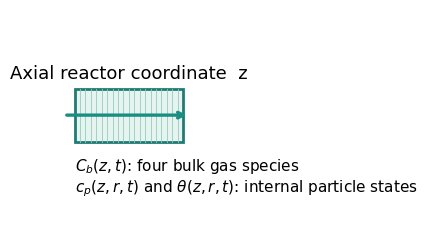

In [2]:
# One diagram; not a simulation output.
fig, ax = plt.subplots(figsize=(10.5, 2.75))
ax.set_xlim(-.05, 1.05); ax.set_ylim(-.8, .8); ax.set_aspect('equal'); ax.axis('off')
ax.add_patch(plt.Rectangle((.05, -.20), .82, .40, facecolor='#e6f4f0', edgecolor='#217b74', lw=2))
for i in range(1, 20):
    x=.05+.82*i/20
    ax.plot([x,x],[-.20,.20],color='#98cbc0',lw=.6)
ax.annotate('',xy=(.92,0),xytext=(-.03,0),arrowprops=dict(arrowstyle='->',lw=2.4,color='#1a8e83'))
ax.text(.46,.28,'Axial reactor coordinate  z',ha='center',fontsize=13)
ax.text(.05,-.42,r'$C_b(z,t)$: four bulk gas species',fontsize=11)
ax.text(.05,-.58,r'$c_p(z,r,t)$ and $\theta(z,r,t)$: internal particle states',fontsize=11)
plt.show()

## 02 · Method of Lines: space becomes a vector

Start with a distributed balance in axial position \(z\) and time \(t\). A schematic advection–reaction equation is

\[
\frac{\partial C_b}{\partial t}
= -v\frac{\partial C_b}{\partial z} + \underbrace{S_b(C_b,c_p,\theta)}_{\text{mass-transfer / reaction coupling}}.
\]

The project also tracks **radial diffusion inside spherical catalyst particles**. Discretize both spatial coordinates, but **do not discretize time at this stage**:

\[
\frac{\mathrm d\mathbf y}{\mathrm dt}=F(t,\mathbf y;\mathbf p),\qquad
\mathbf y=\big[C_b\mid c_p\mid\theta\big].
\]

For one right-moving bulk concentration, first-order upwind differencing gives

\[
\frac{\mathrm d C_i}{\mathrm dt}= -\frac{v}{\Delta z}(C_i-C_{i-1})
\quad\text{(transport only; no reaction).}
\]

This is the numerical bridge: **PDE → spatial grid → ODE system → time integrator**.

In [3]:
# Extract a clean, inspectable mathematical core.
L = 0.50       # m; demo values matching the scaffold's geometry
u_superficial = 0.10  # m/s
bed_void_fraction = 0.40
u_interstitial = u_superficial / bed_void_fraction
z = (np.arange(N_z) + 0.5) * (L / N_z)
dz = L / N_z

# Numerical comparison: check the spherical r=0 symmetry coefficient.
# For c(r) = r², ∇²c = 6 everywhere in three dimensions.
dr = 0.002 / (N_r - 1)
r = np.arange(N_r) * dr
c = r**2
laplacian_at_center = 6 * (c[1] - c[0]) / dr**2
assert np.isclose(laplacian_at_center, 6.0)
print('One spherical-center consistency check: ∇²(r²) =', laplacian_at_center)
print('The complete model still requires the documented independent audit fixes.')

One spherical-center consistency check: ∇²(r²) = 6.0
The complete model still requires the documented independent audit fixes.


## ↪ Presentation detour · Why these numerical choices?

**This is the place to rotate the HTML carousel away from the notebook.**

- **Axial advection:** upwind/backward spatial difference aligns with the flow direction and avoids spurious oscillations for simple convection-dominated transport, at the cost of numerical diffusion.
- **Intraparticle diffusion:** central differences are suitable in the interior; spherical symmetry at \(r=0\) needs special handling.
- **Time integration:** an implicit **BDF** method is a sensible candidate for a stiff reaction–transport ODE system. The solver's success is *not* itself proof of physical correctness.

**Compare with alternatives:** central advection can oscillate; explicit time integration may demand small steps for stiff chemistry; direct steady-state solving removes the time history that this BEP aims to investigate.

> Rotation back → continue directly below, where we run a **transport-only demonstration**. This is deliberately not the scaffold's (currently unparameterized) chemistry.

## 03 · What a transient looks like

First we show a reproducible numerical effect without pretending to know missing reaction-rate constants.

We simulate a **single inert tracer** traversing the reactor. There is no adsorption, no radial diffusion, and no reaction in the following code. That isolates the transport component and produces a credible step-response demonstration.

\[
C_{\mathrm{in}}(t)=\tfrac12\left[1+\tanh\left(\frac{t-t_0}{\delta}\right)\right]
\]

The smooth step is a convenient demonstration input rather than experimental data.

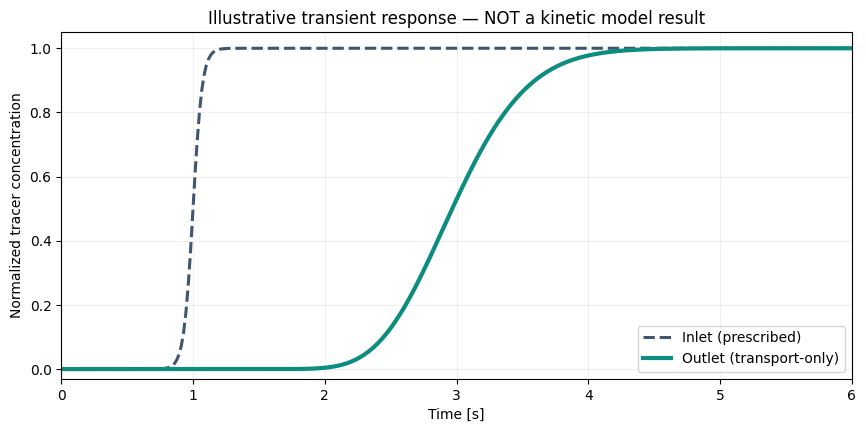

BDF integration: 876 right-hand-side evaluations, success=True


In [4]:
def inlet_tracer(t, switch_time=1.0, switch_width=0.07):
    return 0.5 * (1.0 + np.tanh((t - switch_time) / switch_width))

def transport_only_rhs(t, y):
    # Pure 1D upwind advection; intentionally does not mutate the input vector.
    upstream = np.concatenate(([inlet_tracer(t)], y[:-1]))
    return -(u_interstitial / dz) * (y - upstream)

start_state = np.zeros(N_z)
state_before = start_state.copy()
times = np.linspace(0, 6, 350)
sol = solve_ivp(
    transport_only_rhs, (times[0], times[-1]), start_state,
    method='BDF', t_eval=times, rtol=2e-8, atol=1e-10,
)
assert sol.success, sol.message
assert np.array_equal(start_state, state_before), 'Unexpected mutation!'
assert sol.y.shape == (N_z, times.size)
assert np.min(sol.y) >= -1e-7 and np.max(sol.y) <= 1 + 1e-7

fig, ax = plt.subplots(figsize=(10.2, 4.5))
ax.plot(sol.t, [inlet_tracer(t) for t in sol.t], lw=2.2,
        color='#41556f', linestyle='--', label='Inlet (prescribed)')
ax.plot(sol.t, sol.y[-1], lw=3, color='#0d8c80', label='Outlet (transport-only)')
ax.set(xlabel='Time [s]', ylabel='Normalized tracer concentration',
       title='Illustrative transient response — NOT a kinetic model result',
       xlim=(0,6),ylim=(-0.03,1.05))
ax.grid(alpha=.2); ax.legend(loc='lower right');plt.show()
print(f'BDF integration: {sol.nfev} right-hand-side evaluations, success={sol.success}')

## 04 · What we can and cannot conclude

**The structural achievement:** a transport–diffusion–surface-kinetics formulation can be organized as a state-space model, and Method of Lines converts its spatial balances into a large ODE system.

**The numerical illustration:** a reproducible BDF solution produces a delayed outlet transient **for transport only**. It does **not** demonstrate conversion, selectivity, kinetic fitting, or agreement with experiments.

**What the current source needs next:** populate kinetic parameters with traceable literature evidence; resolve the documented numerical defects (including state mutation, spherical-center handling, and surface-coverage boundary behavior); test mass balances, refinement, and independent benchmarks before claiming chemical predictions.

> **Return to the research story:** With sufficiently described internal states, the model can evolve from the present state and imposed inputs rather than requiring an arbitrary explicit dependence on the whole measurement history. Whether this particular state description is sufficient is a modelling and validation question—not yet a proven conclusion.

### Source / provenance
- [Executable scaffold: `3_Model/c2h2_hydrogenation_transient_model.py`](https://github.com/AsapLoso/project-management-agents/blob/devcontainer/Academics/BEP/Catalysis/3_Model/c2h2_hydrogenation_transient_model.py)
- [Known issues and audit: `3_Model/state.md`](https://github.com/AsapLoso/project-management-agents/blob/devcontainer/Academics/BEP/Catalysis/3_Model/state.md)
- [Presentation sub-narrative](https://github.com/AsapLoso/project-management-agents/blob/devcontainer/Academics/BEP/Catalysis/presentation/sub-stories/01_three_concentrations_to_state_space.md)

*Notebook version 1 — 13 October 2026. Source materials may change; verify current implementation before presenting experimental outcomes.*